# 1. Objective

Use option price to recover the implied volatility $\sigma_{imp}$ via two different methods:

- Bisection Method

- Newton Iteration

and compare the convergence rate. In this experiment, synthetic option prices are generated from the Black–Scholes model with prescribed volatility values.

# 2. Methodology

## 2.1 BS formula and validity

We take European put option with continuous dividend yield for example. The Black-Scholes formula gives

$$
P_{BS}(\sigma)=Ke^{-rT}N(-d_2)-S_0e^{-qT}N(-d_1),
$$

where 

$$
d_1=\frac{1}{\sigma \sqrt{T}}\left(\log (S_0/K)+(r-q+\frac{1}{2}\sigma^2)T\right),\qquad d_2=d_1-\sigma \sqrt{T}.
$$

Letting $\sigma \to 0$ and $\sigma \to \infty$ to get the limits

$$
\lim_{\sigma\to 0^+}P_{BS}(\sigma)=\max(Ke^{-rT}-S_0e^{-qT},0), \qquad \lim_{\sigma\to \infty}P_{BS}(\sigma)=Ke^{-rT}. 
$$

Denote 

$$
f(\sigma)=P_{BS}(\sigma)-P_{mkt},
$$

the implied volatility $\sigma_{imp}$ is such that the BS price $P_{BS}(\sigma)$ equals the market price $P_{mkt}$, hence we derive $f(\sigma_{imp})=0$.

The Greek letter Vega is 

$$
\mathrm{Vega}=\frac{\partial P_{BS}}{\partial \sigma}=S_0e^{-qT}\sqrt{T}\varphi(d_1),
$$

$$
\varphi(x)=\frac{1}{\sqrt{2\pi}}e^{-x^2/2},
$$

$\varphi$ is the probability density function of standard normal distribution. Since $\partial_{\sigma} P_{BS}>0$, the European put price $P_{BS}$ 

$$
P_{BS}:\ (0,+\infty)\to \left(\max(Ke^{-rT}-S_0e^{-qT},0),Ke^{-rT}\right)
$$


is bijective and strictly increasing in sigma, we can find the only positive number $\sigma_{imp}$ satisfying

$$
P_{BS}(\sigma_{imp})=P_{mkt}. 
$$

## 2.2 Bisection Method

Suppose $f$ is continuous on $[a,b]$ and 

$$
f(a)<0,\qquad f(b)>0,
$$

there exists zero point $x^*\in[a,b]$. Take middle point $c=(a+b)/2$, we have three cases:

- $f(c)<0$, zero point in $[c,b]$

- $f(c)>0$, zero point in $[a,c]$

- $f(c)=0$, find zero point $c$
 
Define 

$$
e_n=x_n-x^*
$$

be the error after $n$-th iteration. We have 

$$
b_n-a_n=\frac{b_0-a_0}{2^n},\qquad x_n=\frac{a_n+b_n}{2},
$$

and thus 

$$
|e_n|=|x_n-x^*|\le \frac{b_0-a_0}{2^{n+1}}.
$$

The convergence order of bisection is $1$.

## 2.3 Newton's Method

Apply Taylor expansion around $x_n$ for function $f(x)$

$$
f(x)\approx f(x_n)+f'(x_n)(x-x_n).
$$

Let RHS equals zero, we get the iteration formula

$$
x_{n+1}=x_{n}-\frac{f(x_n)}{f'(x_n)}. 
$$

In our setting, 

$$
f(\sigma)=P_{BS}(\sigma)-P_{mkt},
$$

$$
f'(\sigma)=\mathrm{Vega}(\sigma)=S_0 e^{-qT}\sqrt{T}\varphi(d_1). 
$$

Subscribe the above equations into Newton's method to get 

$$
\sigma_{n+1}=\sigma_n-\frac{P_{BS}(\sigma_n)-P_{mkt}}{\mathrm{Vega}(\sigma_n)}. 
$$

**Convergence Order** 

Here we assume 

- $f$ is continuous and differential around $x^*$ up to second order

- $f'(x^*)\neq 0$

- the initial point $\sigma_0$ is close to actural root $\sigma_{true}$

Expand $f(x)$ around $x_n$ up to second order 

$$
f(x)=f(x_n)+f'(x_n)(x-x_n)+\frac{1}{2}f''(\xi_n)(x-x_n)^2,
$$

where $\xi_n$ lies between $x$ and $x_{n}$. 
Denote $x=x^*$ and remember that $e_n=x_n-x^*$,

$$
f(x^*)=0=f(x_n)-f'(x_n)e_n+\frac{1}{2}f''(\xi_n)e_n^2,
$$

this derives 

$$
\frac{f(x_n)}{f'(x_n)}=e_n-\frac{f''(\xi_n)}{2f'(x_n)}e_n^2.
$$

We finally have 

$$
\begin{aligned}
e_{n+1}&=x_{n+1}-x^*\\
&=x_n-\frac{f(x_n)}{f'(x_n)}-x^*\\
&=\frac{f''(\xi_n)}{2f'(x_n)}e_n^2,
\end{aligned}
$$

$$
\lim_{n\to \infty}\frac{e_{n+1}}{e_n^2}=\frac{f''(x^*)}{2f'(x^*)}. 
$$

Newton's method holds second order convergence locally.

# 3. Experiment Design

Consider a $5$-month European put option on a dividend-paying stock when the stock price is $\$50$, the strike price is $\$50$, the risk-free interest rate is $10\%$ per annum, the continuous dividend yield is $0.3\%$ and the volatility is $40\%$ per annum. This means that $S_0=50,K=50,r=0.1,q=0.003,\sigma=0.4,T=5/12$.

# 4. Numerical Implementation

In [11]:
import sys
from pathlib import Path

PROJECT_ROOT=Path.cwd().parent
SRC_DIR=PROJECT_ROOT/'src'

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0,str(SRC_DIR))

print(str(SRC_DIR) in sys.path)

True


In [21]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt

import black_scholes as bs
import greeks as gk
import implied_volatility as iv

# Set parameters
S0=50;K=50;T=5/12;r=0.1;q=0.003;sigma=0.4

sigma_true=[0.2,0.4,0.6,0.8,1.0]

# test validity
for sigma in sigma_true:
    # put price form BS formula
    put_bs=bs.bs_calculator(S0,K,T,r,q,sigma,option_type='put')

    # Set market price as BS price
    mkt_price=put_bs
    print(f'\nsigma={sigma}, mkt_price={mkt_price}')

    # bisection method
    sigma_bi,n_bi,*_=iv.bisection(S0,K,T,r,q,mkt_price)
    print(f'Bisection: sigma={sigma_bi}, iterations={n_bi}')

    # Newton's method
    sigma_nt,n_nt,*_=iv.Newton(S0,K,T,r,q,mkt_price,initial_sigma=0.3)
    print(f'Newton: sigma={sigma_nt}, iterations={n_nt}')


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload

sigma=0.2, mkt_price=1.652490684249365
Bisection: sigma=0.20000000352965172, iterations=27
Newton: sigma=0.20000000000001034, iterations=4

sigma=0.4, mkt_price=4.1001316966328964
Bisection: sigma=0.40000000450988393, iterations=27
Newton: sigma=0.3999999999999999, iterations=4

sigma=0.6, mkt_price=6.5673531324574235
Bisection: sigma=0.600000005490116, iterations=27
Newton: sigma=0.6000000000000005, iterations=4

sigma=0.8, mkt_price=9.013910582016567
Bisection: sigma=0.8000000064703484, iterations=27
Newton: sigma=0.8000000000000006, iterations=4

sigma=1.0, mkt_price=11.423979859790432
Bisection: sigma=0.9999999925494195, iterations=27
Newton: sigma=0.9999999999999912, iterations=4


## 4.1 Convergence rate

Iteration 1: q = 1.099893e-01
Iteration 2: q = 8.979119e-03


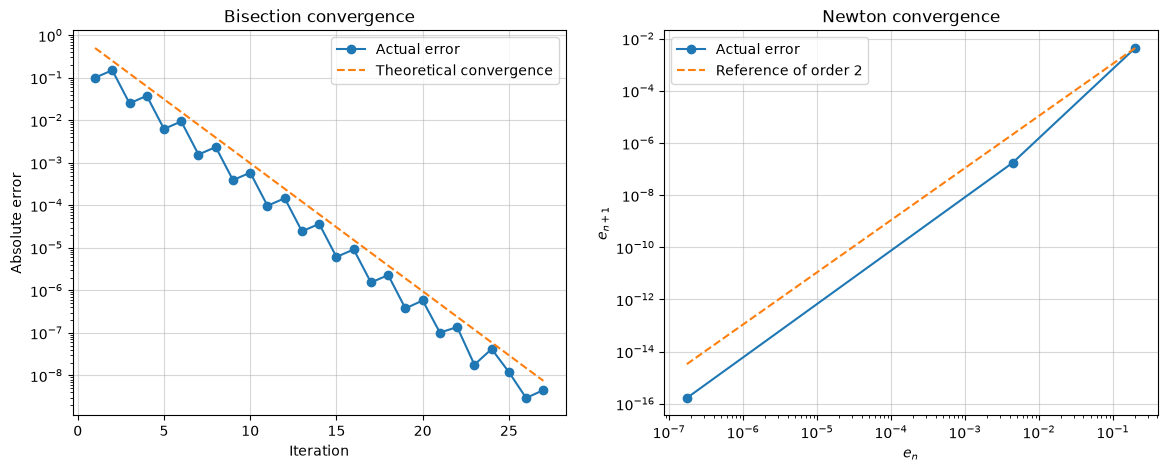

In [22]:
# Plot convergence rate
sigma_true=0.4

# Set market price as BS price
mkt_price=bs.bs_calculator(S0,K,T,r,q,sigma_true,option_type='put')

# bisection
sigma_bi,n_bi,history_bi=iv.bisection(S0,K,T,r,q,mkt_price)
N_bi=np.arange(1,len(history_bi)+1)
error_bi=np.abs(np.array(history_bi)-sigma_true)

# theoretical error reference
a0=1e-8
b0=1.0
error_ref=(b0-a0)/(2.0**N_bi)

fig,axes=plt.subplots(1,2,figsize=(14,5))


axes[0].semilogy(N_bi,error_bi,'o-',label='Actual error')
axes[0].semilogy(N_bi,error_ref,'--',label='Theoretical convergence')
axes[0].set_xlabel('Iteration')
axes[0].set_ylabel('Absolute error')
axes[0].set_title('Bisection convergence')
axes[0].legend()
axes[0].grid(alpha=0.5)


# Newton's method
sigma_nt,n_nt,history_nt=iv.Newton(S0,K,T,r,q,mkt_price,initial_sigma=0.2)
N_nt=np.arange(1,len(history_nt)+1)
error_nt=np.abs(np.array(history_nt)-sigma_true)
error_ref2=error_nt[:-1]**2/error_nt[0]**2*error_nt[1]

axes[1].loglog(error_nt[:-1],error_nt[1:],'o-',label='Actual error')
axes[1].loglog(error_nt[:-1],error_ref2,'--',label='Reference of order 2')
axes[1].set_xlabel(r'$e_n$')
axes[1].set_ylabel(r'$e_{n+1}$')
axes[1].set_title("Newton convergence")
axes[1].legend()
axes[1].grid(alpha=0.5)

fig.savefig(
    PROJECT_ROOT/'figures'/'04_iv_solver_convergence.png',
    dpi=300,
    bbox_inches='tight'
)

# Verify quadratic convergence
ratio = error_nt[1:] / error_nt[:-1]**2

for i, ratio_value in enumerate(ratio):
    if error_nt[i+1] > 1e-12:
        print(
            f"Iteration {i+1}: "
            f"q = {ratio_value:.6e}"
        )




## 4.2 Stability of Newton's iteration

Fix parameter

$$
S0=100,\quad r=0.1,\quad\sigma_{true}=0.4,
$$

we investigate the robustness of Newton's method by varying the strike price $K$, time to maturity $T$, and initial volatility $\sigma_0$.

$$
K\in \left\{ 70,85,100,115,130\right\},
$$

$$
T\in \left\{1,0.25,0.05,0.01\right\},
$$

and 

$$
\sigma_0 \in \left\{0.05,0.1,0.3,0.8,1.5\right\}.
$$


Results
     K    T  initial_sigma       Vega  estimated_sigma   sigma_error  \
0  70  1.0           0.05  16.333263              NaN           NaN   
1  70  1.0           0.10  16.333263              NaN           NaN   
2  70  1.0           0.30  16.333263              0.4  1.684597e-11   
3  70  1.0           0.80  16.333263              0.4  1.399468e-10   
4  70  1.0           1.50  16.333263              0.4  2.585566e-10   

   iterations           status  accurate  
0           1   vega_too_small     False  
1           2   vega_too_small     False  
2           5  price_tolerance      True  
3           5  price_tolerance      True  
4           5  price_tolerance      True  
Failed cases
       K     T  initial_sigma          Vega  sigma_error           status
0    70  1.00           0.05  1.633326e+01          NaN   vega_too_small
1    70  1.00           0.10  1.633326e+01          NaN   vega_too_small
5    70  0.25           0.05  2.672660e+00          NaN   vega_too_small


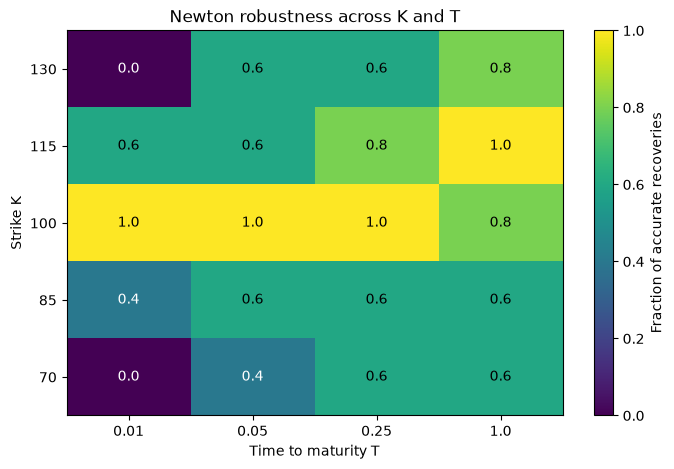

      K     T  success_rate  avg_iterations          vega
0    70  0.01           0.0             5.0  1.457460e-17
1    70  0.05           0.4             5.6  2.107370e-03
2    70  0.25           0.6             4.8  2.672660e+00
3    70  1.00           0.6             3.6  1.633326e+01
4    85  0.01           0.4             5.6  8.665205e-04
5    85  0.05           0.6             4.8  1.422988e+00
6    85  0.25           0.6             3.8  1.168046e+01
7    85  1.00           0.6             3.8  2.774355e+01
8   100  0.01           1.0             3.2  3.985399e+00
9   100  0.05           1.0             3.6  8.875728e+00
10  100  0.25           1.0             3.8  1.945023e+01
11  100  1.00           0.8             4.0  3.606520e+01
12  115  0.01           0.6             7.2  1.038972e-02
13  115  0.05           0.6             4.2  3.055962e+00
14  115  0.25           0.8             4.6  1.778407e+01
15  115  1.00           1.0             4.4  3.960274e+01
16  130  0.01 

In [19]:
# Stability of Newton's method
import pandas as pd 
S0=100;r=0.1;sigma_true=0.4

K_values=[70,85,100,115,130]
T_values=[1.0,0.25,0.05,0.01]
initial_values=[0.05,0.1,0.3,0.8,1.5]

rows=[]

for K in K_values:
    for T in T_values:

        # actual market price and vega
        market_price=bs.bs_calculator(S0,K,T,r,q,sigma_true,option_type='put')
        *_,true_vega=gk.bs_greeks(S0,K,T,r,q,sigma_true,option_type='put')

        for sigma0 in initial_values:
            estimate,n,status=iv.Newton_tracking(S0,K,T,r,q,market_price,initial_sigma=sigma0)

            sigma_error=abs(estimate-sigma_true)

            # determine whether solve correctly
            accurate=(
                np.isfinite(estimate) and sigma_error<1e-4
            )

            rows.append({
                'K':K,
                'T':T,
                'initial_sigma':sigma0,
                'Vega':true_vega,
                'estimated_sigma':estimate,
                'sigma_error':sigma_error,
                'iterations':n,
                'status':status,
                'accurate':accurate
            })
results=pd.DataFrame(rows)
print('Results\n',results.head())

results.to_csv(PROJECT_ROOT/'data'/'processed'/'Newton stability.csv',index=False)

# Failed cases
failed=results.loc[~results['accurate'],['K','T','initial_sigma','Vega','sigma_error','status']]
print('Failed cases\n',failed)

# Count different failure reasons
print(results['status'].value_counts())
# Plot
success=results.pivot_table(
    index='K',
    columns='T',
    values='accurate',
    aggfunc='mean'
)

fig,ax=plt.subplots(figsize=(8,5))

im=ax.imshow(
    success.values,
    aspect='auto',
    origin='lower',
    vmin=0,
    vmax=1
)

for i in range(success.shape[0]):
    for j in range(success.shape[1]):
        value=success.iloc[i,j]

        ax.text(
            j,i,
            f'{value:.1f}',
            ha='center',
            va='center',
            color='white' if value <0.5 else 'black'
        )

ax.set_xticks(
    range(len(success.columns)),
    success.columns 
)
ax.set_yticks(
    range(len(success.index)),
    success.index 
)

ax.set_xlabel('Time to maturity T')
ax.set_ylabel('Strike K')
ax.set_title('Newton robustness across K and T')

fig.colorbar(
    im,ax=ax,
    label='Fraction of accurate recoveries'
)

plt.show()

fig.savefig(
    PROJECT_ROOT/'figures'/'04_newton_stability_heatmap.png',
    dpi=300,
    bbox_inches='tight'
)

# summary

summary=results.groupby(['K','T']).agg(
    success_rate=('accurate','mean'),
    avg_iterations=('iterations','mean'),
    vega=('Vega','first')
).reset_index()

print(summary)

# 5. Conclusions

In this project, we implemented two numerical methods to recover the implied volatility of a European put option using the Black–Scholes pricing formula.

**1. Numerical accuracy**

Both Bisection and Newton's methods successfully recovered the prescribed volatility values from synthetic option prices. Newton's method required fewer iterations than Bisection in the tested cases.

**2. Convergence behavior**

- Bisection provides a reliable linear convergence guarantee through successive interval reduction.
- Newton's method exhibits local quadratic convergence when the initial guess is sufficiently close to the root and the derivative is nonzero.

**3. Numerical stability**

The robustness of Newton's method depends on the strike price, time to maturity, and initial volatility.

When Vega becomes very small, the implied volatility becomes more sensitive to pricing errors:

$$
\frac{\partial \sigma_{\mathrm{imp}}}{\partial P_{\mathrm{mkt}}}
=\frac{1}{\mathrm{Vega}}.
$$

Consequently, Newton's method may encounter excessively large iteration steps or inaccurate recovery of implied volatility.

**4. Further improvement**

A safeguarded Newton method, combining Newton iteration with a bracketing method, can improve numerical robustness.